# Hα Flux Map - Variable (Auto) Colour Scale

Counterpart to `flux_map_fixed_scale.ipynb`: same data and layout, but
each panel is colour-scaled to **its own** min/max instead of a shared
fixed range.

**Use this one when:** you want to see the internal structure of each
galaxy's Hα emission as clearly as possible (where the flux is
concentrated, its morphology) - auto-scaling always uses the full colour
range for whatever data is there, so faint galaxies don't look washed out.

**Use `flux_map_fixed_scale.ipynb` instead when:** the point is comparing
*absolute* brightness between galaxies (e.g. "galaxies above the SFMS have
genuinely higher Hα flux, not just different internal structure") - that
comparison isn't meaningful here, since each panel below has already been
stretched to fill its own colour range regardless of its actual flux level.

Because each panel's scale differs, each gets **its own colorbar** (a
single shared colorbar across differently-scaled panels would misrepresent
at least two of them).

In [10]:
%matplotlib inline

import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Jupyter's default cwd is the notebook's own directory (sami_sf_pipeline/notebooks/).
PIPELINE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PIPELINE_ROOT / "data" / "raw").exists(), (
    f"Couldn't find data/raw under {PIPELINE_ROOT} - "
    "run this notebook from sami_sf_pipeline/notebooks/, or adjust PIPELINE_ROOT above."
)
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.io import read_sami_halpha_layers
from src.utils.plotting import plot_map

RAW_HALPHA_DIR = PIPELINE_ROOT / "data" / "raw" / "sami_dr3_Halpha_maps"
OUT_FIGURE_DIR = PIPELINE_ROOT / "outputs" / "figures" / "flux_maps"
CSV_DIR = PIPELINE_ROOT / "outputs" / "csv"


def find_halpha_fits(catid: int) -> Path:
    """Locate the raw 1-comp Halpha FITS file for a CATID (same matching as 01_flux_map.py)."""
    matches = sorted(RAW_HALPHA_DIR.glob(f"{catid}_*_Halpha_default_1-comp.fits"))
    if not matches:
        raise FileNotFoundError(f"No raw Halpha FITS found for CATID {catid} in {RAW_HALPHA_DIR}")
    if len(matches) > 1:
        print(f"  Warning: {len(matches)} files matched CATID {catid} - using {matches[0].name}")
    return matches[0]

## Configuration - edit this cell, then re-run it and whichever section you need below

No `FLUX_VMIN`/`FLUX_VMAX` here - that's the whole point of this notebook.

In [14]:
CATID = 14812        # <-- single-galaxy section
LAYER = "sum"        # "sum" (summed flux) or "fit" (Gaussian fit) - same choice as 01_flux_map.py
CMAP = "YlOrRd"      # <-- matplotlib colormap name, e.g. "viridis", "inferno", "magma", "plasma"

COMPARE_CATIDS = [77967, 14812, 107528]   # <-- comparison-panel section: above, on, below MS

## Single galaxy

In [12]:
fits_path = find_halpha_fits(CATID)
flux_layers, err_layers, header, meta = read_sami_halpha_layers(str(fits_path))
flux_map = flux_layers[LAYER]

print(f"Loaded: {fits_path.name}")
print(f"  Flux range (finite pixels): {np.nanmin(flux_map):.4g} - {np.nanmax(flux_map):.4g}  (auto-scaled to this range)")

OUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
outfile = OUT_FIGURE_DIR / f"{CATID}_Halpha_{LAYER}_variablescale.png"
plot_map(
    flux_map,
    title=f"CATID {CATID} - raw H\u03b1 flux ({LAYER})",
    outfile=str(outfile),
    cmap=CMAP,
)
print(f"Saved -> {outfile}")

Loaded: 17314_A_Halpha_default_1-comp.fits
  Flux range (finite pixels): 0.0006607 - 0.4488  (auto-scaled to this range)
Saved -> /Users/sophiesinclair/Desktop/sami copy/sami_sf_pipeline/outputs/figures/flux_maps/17314_Halpha_sum_variablescale.png


## Comparison panel (e.g. above / on / below the SFMS)

Each panel is scaled independently to its own min/max, with its own
colorbar underneath showing that panel's actual flux range - compare these
ranges to see how different the absolute brightness really is, even though
the images themselves look similarly "full" of colour.

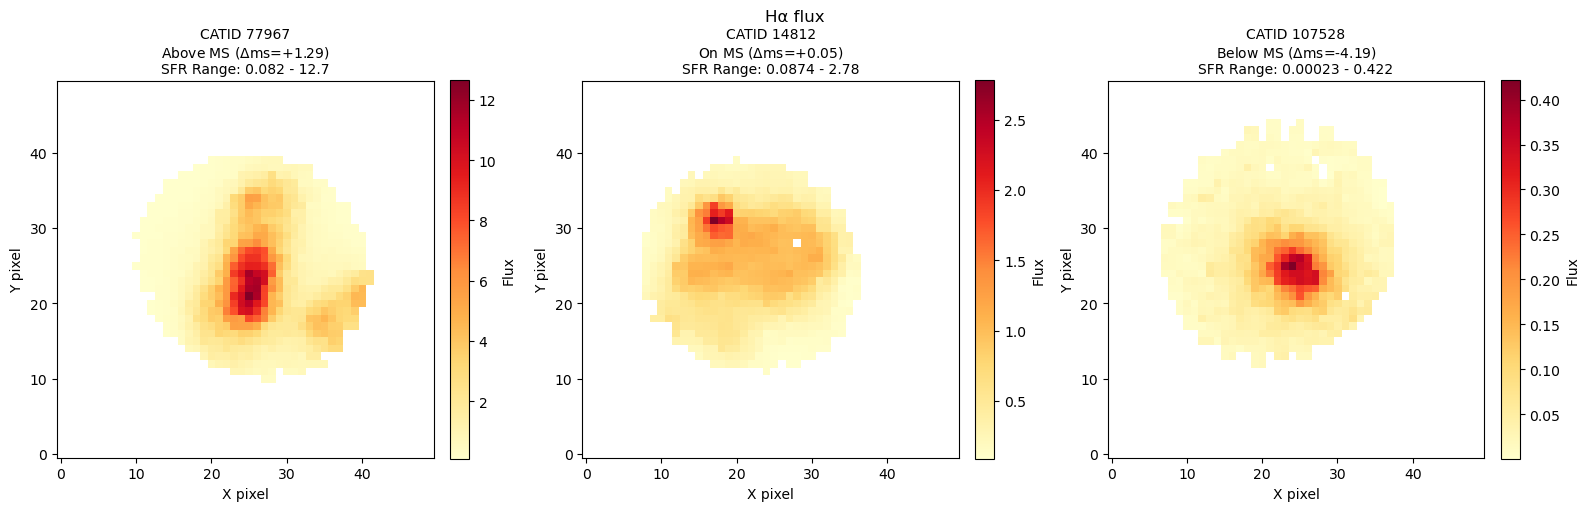

Saved -> /Users/sophiesinclair/Desktop/sami copy/sami_sf_pipeline/outputs/figures/flux_maps/sfms_comparison_flux_maps_variablescale.png


In [15]:
# Optional: label each panel with its SFMS position, if sfms_explorer.ipynb has been run.
MASTER_SFMS_PATTERN = re.compile(r"^master_sfms_(\d{4}-\d{2}-\d{2})\.csv$")
sfms_candidates = sorted(p for p in CSV_DIR.glob("master_sfms_*.csv") if MASTER_SFMS_PATTERN.match(p.name))

sfms_lookup = {}
if sfms_candidates:
    master_sfms = pd.read_csv(sfms_candidates[-1])
    SFMS_BAND_DEX = 0.3
    for _, row in master_sfms.iterrows():
        dm = row.get("delta_ms", np.nan)
        if pd.isna(dm):
            continue
        elif dm > SFMS_BAND_DEX:
            label = f"Above MS ($\\Delta$ms={dm:+.2f})"
        elif dm < -SFMS_BAND_DEX:
            label = f"Below MS ($\\Delta$ms={dm:+.2f})"
        else:
            label = f"On MS ($\\Delta$ms={dm:+.2f})"
        sfms_lookup[int(row["CATID"])] = label
else:
    print("No master_sfms_<date>.csv found - panel titles will show CATID only. Run 05_sfms.py for delta_ms labels.")

fig, axes = plt.subplots(1, len(COMPARE_CATIDS), figsize=(5 * len(COMPARE_CATIDS) + 1, 5))
if len(COMPARE_CATIDS) == 1:
    axes = [axes]

for ax, catid in zip(axes, COMPARE_CATIDS):
    fits_path = find_halpha_fits(catid)
    flux_layers, _, _, _ = read_sami_halpha_layers(str(fits_path))
    flux_map = flux_layers[LAYER]
    fmin, fmax = np.nanmin(flux_map), np.nanmax(flux_map)

    # No vmin/vmax passed - plot_map auto-scales this panel to its own data.
    im = plot_map(flux_map, cmap=CMAP, ax=ax)
    # Own colorbar per panel, since each panel's scale is different - a single
    # shared colorbar would misrepresent at least two of the three panels here.
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Flux")

    subtitle = f"\n{sfms_lookup[catid]}" if catid in sfms_lookup else ""
    ax.set_title(f"CATID {catid}{subtitle}\nSFR Range: {fmin:.3g} - {fmax:.3g}", fontsize=10)

fig.suptitle("H\u03b1 flux", fontsize=12)
plt.tight_layout()

compare_outfile = OUT_FIGURE_DIR / "sfms_comparison_flux_maps_variablescale.png"
OUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(compare_outfile, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved -> {compare_outfile}")